# P7.11 — Passa-faixa FIR com janela de Hamming

*FIR · passa-faixa · janela de Hamming · Tabela 7.1*

> Notebook gerado de `content/p7_11.py`, a mesma fonte da aplicação DSP Filter Lab e do relatório PDF. Para alterar o texto, edite o conteúdo e rode `tools/run_notebook.sh p7_11`.

In [1]:
# Configuração do ambiente (local ou Google Colab)
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    # No Colab, disponibilize o projeto em PROJECT_DIR antes de executar:
    #   (a) Arquivos → upload de dsp-avaliacao-2.zip e  !unzip -q dsp-avaliacao-2.zip
    #   (b) ou monte o Drive:  from google.colab import drive; drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/dsp-avaliacao-2")
    %pip install -q -r {PROJECT_DIR}/requirements.txt
else:
    PROJECT_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())

for p in (PROJECT_DIR, PROJECT_DIR / "src"):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))
print("Projeto em:", PROJECT_DIR)

Projeto em: /mnt/storage/projects/dsp-avaliacao-2


## 1. Enunciado original

> *Design a bandpass filter using the Hamming window design technique. The specifications are: lower stopband edge: 0.3π, As = 50 dB; upper stopband edge: 0.6π; lower passband edge: 0.4π, Rp = 0.5 dB; upper passband edge: 0.5π. Plot the impulse response and the magnitude response (in dB) of the designed filter. Do not use the fir1 function.*

Fonte: DTA §2.1 item 3 e §4 (Resolução P7.11); Ingle & Proakis, p. 379.

## 2. O que está sendo pedido


Projetar um **filtro FIR passa-faixa** estreito (passagem entre $0.4\pi$ e $0.5\pi$) com a **janela de Hamming**.

- Ondulação na passagem de no máximo $R_p = 0.5$ dB.
- Atenuação de pelo menos $A_s = 50$ dB nas duas rejeições.

O enunciado pede $h(n)$ e a magnitude em dB. O procedimento é o do P7.10, agora para um passa-faixa.

## 3. Dados e especificações

| Grandeza | Valor | Origem | Significado |
|---|---|---|---|
| Rejeição inferior | $0 \le \omega \le 0.3\pi$ | ■ Dado do enunciado | a ser atenuada |
| Passagem | $0.4\pi \le \omega \le 0.5\pi$ | ■ Dado do enunciado | a ser preservada |
| Rejeição superior | $0.6\pi \le \omega \le \pi$ | ■ Dado do enunciado | a ser atenuada |
| $R_p$ | 0.5 dB | ■ Dado do enunciado | ondulação máxima na passagem |
| $A_s$ | 50 dB | ■ Dado do enunciado | atenuação mínima |
| Método | janela de Hamming, sem `fir1` | ■ Dado do enunciado | imposto pelo enunciado |


As bordas deste exercício são as mesmas do P7.16, que exige apenas 40 dB e pede o comprimento mínimo. Vale comparar os dois.

## 4. Fundamentação teórica


**Passa-faixa ideal** = diferença de dois passa-baixas ideais, com cortes $\omega_{c1} < \omega_{c2}$.

**Paridade livre.** Um passa-faixa não exige ganho em $\omega = \pi$, que fica na rejeição. Por isso $M$ par (Tipo 2, com $H_r(\pi) = 0$ obrigatório) também é admissível (decisão D4 do plano). Aqui a Tabela 7.1 já dá um valor ímpar.

**Janela de Hamming:** $\Delta\omega \approx 6.6\pi/M$ e $A_s \approx 53$ dB (Tabela 7.1, conforme o DTA).


#### Aprofundamento: A atenuação cresce sempre com M?


Não necessariamente. Ao variar $M$, mudam duas coisas: a largura da transição e a posição exata dos lóbulos em relação às bordas. A varredura do passo 5 mostra $A_s$ maior com $M = 66$ do que com $M = 67$. Por isso "comprimento mínimo" só pode ser afirmado medindo cada candidato (P7.13–P7.16), e não pela fórmula.

## 5. Equações e variáveis

**(1) Comprimento pela Tabela 7.1 (Hamming)** · *DTA §3.1.C*

$$
M = \left\lceil \frac{6.6\pi}{\Delta\omega} \right\rceil + 1
$$



**(2) Janela de Hamming** · *DTA §3.1.C*

$$
w(n) = 0.54 - 0.46\cos\left(\frac{2\pi n}{M-1}\right)
$$



**(3) Resposta ideal do passa-faixa** · *DTA §3.1.E*

$$
h_d(n) = \frac{\sin[\omega_{c2}(n-\alpha)] - \sin[\omega_{c1}(n-\alpha)]}{\pi(n-\alpha)}
$$

Diferença de dois passa-baixas ideais.

| Símbolo | Significado |
|---|---|
| $\alpha = (M-1)/2$ | atraso |

**(4) Filtro projetado** · *DTA §3.1*

$$
h(n) = h_d(n)\,w(n)
$$

## 6. Resolução passo a passo

### Passo 1 — Determinar a largura de transição

As duas transições são iguais.

$$
\Delta\omega = 0.4\pi - 0.3\pi = 0.6\pi - 0.5\pi = 0.1\pi
$$

| Grandeza | Valor | Origem | Significado |
|---|---|---|---|
| $\Delta\omega$ | $0.1\pi$ | ∑ Valor calculado | largura de transição |

### Passo 2 — Conferir a janela e calcular o comprimento

A Hamming é imposta pelo enunciado e atende ao $A_s$ exigido pela tabela (53 ≥ 50 dB).

$$
M = \left\lceil \frac{6.6\pi}{0.1\pi} \right\rceil + 1 = 66 + 1 = 67, \qquad \alpha = 33
$$

| Grandeza | Valor | Origem | Significado |
|---|---|---|---|
| $M$ | 67 | ∑ Valor calculado | comprimento (Tipo 1) |

### Passo 3 — Posicionar as frequências de corte

No meio de cada transição.

$$
\omega_{c1} = \frac{0.3\pi + 0.4\pi}{2} = 0.35\pi, \qquad \omega_{c2} = \frac{0.5\pi + 0.6\pi}{2} = 0.55\pi
$$

| Grandeza | Valor | Origem | Significado |
|---|---|---|---|
| $\omega_{c1}, \omega_{c2}$ | $0.35\pi$, $0.55\pi$ | ∑ Valor calculado | cortes |

### Passo 4 — Construir o filtro e medir

Medição em 20001 frequências, com as bordas.

$$
R_p = 0.0489\ \text{dB}, \qquad A_s = 51.20\ \text{dB}
$$

| Grandeza | Valor | Origem | Significado |
|---|---|---|---|
| $R_p$ | 0.0489 dB | ● Resultado obtido | ≤ 0.5 dB |
| $A_s$ | 51.20 dB | ● Resultado obtido | folga de 1.20 dB; pior ponto em $0.6000\pi$ |

### Passo 5 — Observar os comprimentos vizinhos (complementar)

O enunciado não pede o mínimo, mas a varredura mostra um fato útil para o P7.16:

| $M$ | Tipo | $R_p$ (dB) | $A_s$ (dB) | atende? |
|---|---|---|---|---|
| 62 | 2 | 0.0834 | 42.20 | ✗ não |
| 63 | 1 | 0.0683 | 43.94 | ✗ não |
| 64 | 2 | 0.0624 | 45.71 | ✗ não |
| 65 | 1 | 0.0497 | 49.06 | ✗ não |
| 66 | 2 | 0.0433 | 52.02 | ✓ sim |
| 67 | 1 | 0.0489 | 51.20 | ✓ sim |
| 68 | 2 | 0.0422 | 51.20 | ✓ sim |

$$
M = 66\ (\text{Tipo } 2):\ A_s = 52.02\ \text{dB} \ge 50
$$

| Grandeza | Valor | Origem | Significado |
|---|---|---|---|
| $M = 66$ | atende | ● Resultado obtido | comprimento par (Tipo 2) também atende |

> ⚠️ $M = 66$ também atende, com $A_s$ **maior** que o de $M = 67$. A resposta segue a regra da Tabela 7.1, mas fica claro que a tabela é uma estimativa.

## 7. Implementação computacional


1. **Projeto** (`design_fixed_window(SPEC, "hamming")`): $\Delta\omega$, $M$, cortes e $h(n)$.
2. **Medição** (`validate_fir_db`): $R_p$ e $A_s$ nas grades de 501 e 20001 pontos com as bordas.
3. **Varredura complementar**: o mesmo projeto para cada $M$ de 62 a 68, pares e ímpares.


| Função | O que faz |
|---|---|
| `dsp_av2.fir.design.design_fixed_window` | Passos 1–3 |
| `dsp_av2.fir.ideal.ideal_bandpass` | Resposta ideal do passa-faixa |
| `dsp_av2.validation.validate_fir_db` | Passo 4: mede Rp e As |

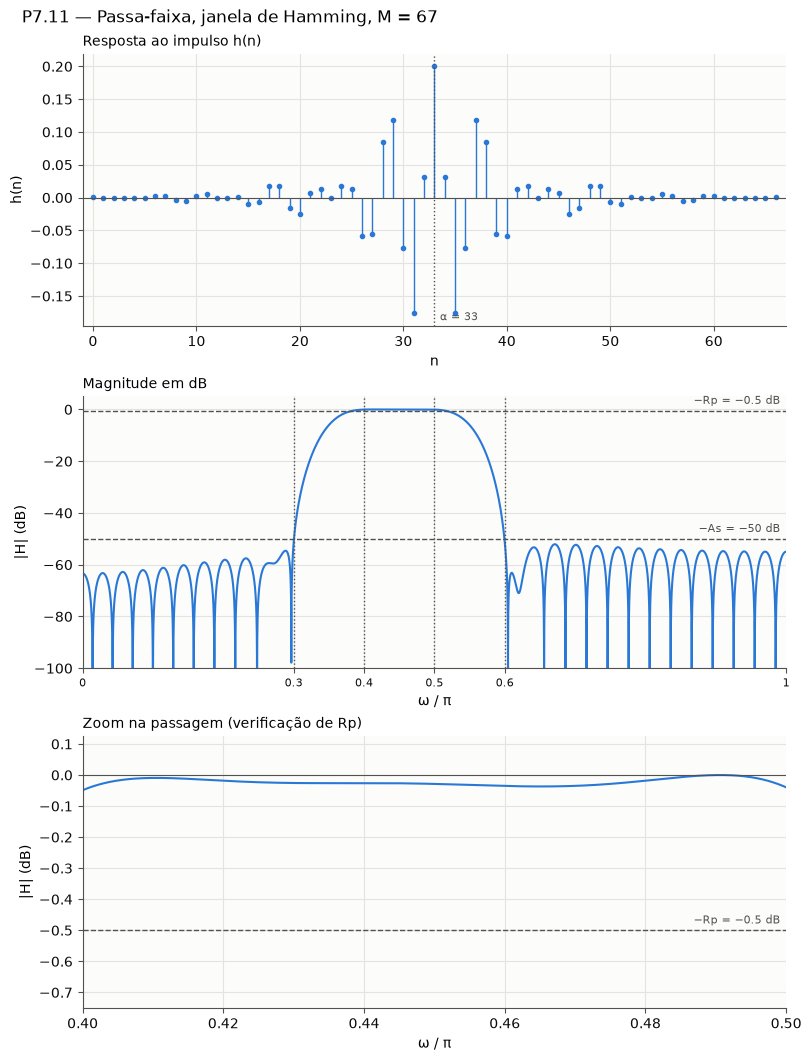

In [2]:
from content import p7_11 as content_mod
objs = content_mod.objects()
import matplotlib.pyplot as plt
from exercises import p7_11
fig = p7_11.plot(objs['final'])
plt.show()

## 8. Gráficos e interpretação

### Resposta ao impulso $h(n)$


Simétrica em torno de $n = 33$ (Tipo 1). A oscilação dos coeficientes tem período próximo de $2\pi/\omega_0$, em que $\omega_0 = (\omega_{c1}+\omega_{c2})/2$ é o centro da passagem.


### Magnitude em dB


Passagem estreita em torno de $0.35\pi$–$0.55\pi$. Os lóbulos das rejeições ficam abaixo de $-50$ dB. O ponto mais crítico é a borda $0.6000\pi$, a −51.20 dB.


### Zoom na passagem (verificação de $R_p$)


Ondulação máxima de 0.049 dB, contra 0.5 dB permitidos.


### $A_s$ medido para comprimentos vizinhos


A atenuação não cresce de forma monotônica com $M$. $M = 66$ (par) atende e supera $M = 67$, que é o valor da Tabela 7.1.

## 9. Verificação das especificações


Critério do livro (dB normalizado, grades com as bordas exatas). $R_p$ é a maior queda na passagem e $A_s$ a menor atenuação nas rejeições.

In [3]:
rep = objs.get('final_report') or objs.get('report')
print(rep)

Validação P7.11 (Tipo 1 de fase linear)
  [OK  ] Rp [dB] (grade livro): 0.0488 <= 0.5000  (folga +0.4512)
  [OK  ] As [dB] (grade livro): 51.2016 >= 50.0000  (folga +1.2016)
  [OK  ] Rp [dB] (grade densa): 0.0489 <= 0.5000  (folga +0.4511)
  [OK  ] As [dB] (grade densa): 51.2017 >= 50.0000  (folga +1.2017)
  Resultado: ATENDE à especificação


## 10. Conclusão técnica


- Hamming com **$M = 67$** (Tipo 1, $\alpha = 33$), cortes em $0.35\pi$ e $0.55\pi$.
- **Atende**: $R_p = 0.049$ dB e $A_s = 51.20$ dB (folga de 1.20 dB).
- $M = 66$ (Tipo 2) também atenderia. A tabela é uma estimativa, e a atenuação não é monotônica em $M$.
- O DTA informa 51.46 dB e 0.0453 dB. A grade de 2049 pontos, que não contém as bordas, dá 51.49 dB e 0.0453 dB, a mesma origem do item V1. Os valores corretos são os medidos com as bordas (V2).